# Train on $D^2_{min}$

For earlier attempts, we trained rearrangement as a binary classification
problem; either particles rearrange, or they don't. We used a cutoff in
$D^2_{min}$ to determine if particles rearranged. This approach worked, but it
had some quirks. 

In [4]:
import torch
# from torch.utils.data import DataLoader, Dataset
from torch import nn
from torch_geometric.nn import GATConv
import torch_geometric.nn as pyg_nn
from torch_geometric.data import Data, Dataset
from torch_geometric.loader import DataLoader
from sklearn.preprocessing import StandardScaler


import numpy as np
import polars as pl
import pandas as pd
import gsd.hoomd
import schmeud
import schmeud._schmeud as schmeud_rs
from schmeud._schmeud import statics
from schmeud import ml
# from tqdm import tqdm

import glob
import os
import pathlib
import pickle
import signac
import freud
from numba import njit

from dataclasses import dataclass
from collections import defaultdict

import matplotlib.pyplot as plt
from scipy import stats
from typing import Union

# from dataset import GlassDataset
# from model import AutoEncoder
from tqdm.notebook import tqdm

In [5]:
from monk import workflow, utils

In [6]:
cwd = pathlib.Path(os.getcwd())
parent = cwd.parent.parent.parent / "config.yaml"
config = workflow.get_config(parent.as_posix())
local = cwd / "config.yaml"
local_config = workflow.get_any_yaml(local.as_posix())
DATA = local_config["data"]
PROJECT: signac.Project = signac.get_project(root=config['root'])
parent, config, local_config

(PosixPath('/home/ian/Projects/work/monk/workflows/2d-osc-shear/config.yaml'),
 {'root': '/media/ian/Data2/monk/2d-osc-shear',
  'origin': '/media/ian/Data2/monk/2d-esl'},
 {'data': '/media/ian/Poppy/improved-nn/qle-v3'})

In [7]:
PROJECT.find_job_ids()

/tmp/ipykernel_2291271/2594364462.py:1: DeprecatedWarning: find_job_ids is deprecated as of 1.3 and will be removed in 2.0. Use find_jobs() instead, then access ids with job.id.Replicate the original behavior with [job.id for job in project.find_jobs()]
  PROJECT.find_job_ids()


['634e14bc75836df75158fb15f379d8bb',
 '7ec2f6aca035e69077eab24383a21cb6',
 'cfa1e4c0007fd65d020f809715a6f0b4',
 'ecce68c50e28a33684826f28780bf6e9',
 '1d0fe2ba44a6f635f5504dcbcee0ebc9',
 '1083a2a09eec2c6cf215ebc7a9706cac',
 '09d3dccc56f1fa9330b57901cd232ab7',
 '6976a7c10ada4159010403f8027f3ea5',
 '9158e73b2e4c9fd1a565e1e5d1bc3af5',
 'c6d7afd0de62bfa16d05da47815227eb',
 'bf92a185d043ce3ef666e05e427c7e76',
 'a8f2c249ed85533b56b0729b7ab96d18']

In [8]:
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")
device

device(type='cpu')

In [9]:
val_data = ["1083a2a09eec2c6cf215ebc7a9706cac", "bf92a185d043ce3ef666e05e427c7e76"]
test_data = ["6976a7c10ada4159010403f8027f3ea5", "a8f2c249ed85533b56b0729b7ab96d18"]

In [10]:
# test HTL = 6976a7c10ada4159010403f8027f3ea5
# test ESL = a8f2c249ed85533b56b0729b7ab96d18
# val HTL = 1083a2a09eec2c6cf215ebc7a9706cac
# val ESL = bf92a185d043ce3ef666e05e427c7e76
# rest are training set

In [8]:
def get_desciptor(file):
    frame = int(utils.extract_between(file, "frame-", ".parquet"))
    cycle = (frame + 1)/40
    max_shear = float(utils.extract_between(file, "shear-", "_period"))
    period = float(utils.extract_between(file, "period-", "_temp"))
    temp = float(utils.extract_between(file, "temp-", "_frame"))
    return {"frame": frame, "cycle": cycle, "max_shear": max_shear, "period": period, "temp": temp}

def get_prep(file, jobs):
    id = file.split("/")[-2]
    return jobs[id].sp["prep"]

class GlassDataset(Dataset):
    def __init__(self, path = None, glob="*", mode="train", filter=None):
        if path is None:
            path = DATA
        # get full path
        path = pathlib.Path(path)
        job_ids = list(PROJECT.find_job_ids())
        # print(job_ids)
        if mode == "train":
            job_ids = [id for id in job_ids if id not in val_data + test_data]
        elif mode == "val":
            job_ids = val_data
        elif mode == "test":
            job_ids = test_data
        elif mode in job_ids:
            job_ids = [mode]
        elif mode == "all":
            pass
        else:
            raise ValueError(f"mode {mode} not recognized")
        
        self._jobs = {id: PROJECT.open_job(id=id) for id in job_ids}
        self._path = path.resolve()
        all_files = []
        descs = []
        for id in job_ids:
            files = list((self._path / id).glob(glob))
            pass_files = []
            for file in files:
                data = np.load(file)
                # if np.mean(data["f16"]) < 1.0:
                pass_files.append(file.as_posix().replace("qle","d2min").replace("npz", "parquet"))
            files = pass_files
            all_files += files
            descs += [get_desciptor(file) for file in files]

        files = all_files
        if filter is not None:
            pair = [(file, desc) for file, desc in zip(files, descs) if filter(desc)]
            files, descs = zip(*pair)
        self._files = files
        self._desc = descs

        gnn_files = [file.replace("parquet", "npz").replace("d2min", "gnn") for file in files]
        self._gnn_files = gnn_files
        for file, desc in zip(self._files, self._desc):
            id = file.split("/")[-2]
            desc["prep"] = get_prep(file, self._jobs)
            desc["id"] = id
        self._len = len(self._files)

    def __len__(self):
        return self._len
    
    def get_info(self, idx):
        file = self._files[idx]
        desc = self._desc[idx]
        data = pd.read_parquet(file)
        return data, desc
    
    def __getitem__(self, idx):
        file = self._files[idx]
        gnn_file = self._gnn_files[idx]
        desc = self._desc[idx]
        data = pd.read_parquet(file)
        gnn_data = np.load(gnn_file)
        qle_data = np.load(gnn_file.replace("gnn", "qle"))
        sfs = np.vstack(data["sfs_rev"].to_numpy())

        shape = sfs.shape
        X = np.zeros((shape[0], 4), dtype=np.float32)
        # strain = data["strain"].to_numpy()
        X[:, 0] = desc["max_shear"]
        X[:, 1] = desc["temp"]
        X[:, 2] = data["soft"].to_numpy()
        X[:, 3] = data["id"].to_numpy()
        # X[:, 4:] = sfs
        tX = torch.tensor(X, dtype=torch.float32)#.to(device)
        # d2min = np.log(data["d2min_right"].to_numpy())
        y = np.log(qle_data["f512"])
        ty = torch.tensor(y, dtype=torch.float32).view(-1, 1)#.to(device)


        qidx = gnn_data["qidx_20"]
        tidx = gnn_data["tidx_20"]

        edge_index = torch.tensor(np.vstack([qidx, tidx]).astype(np.int32), dtype=torch.long)
        edge_attr = torch.tensor(gnn_data["disp_20"], dtype=torch.float32)

        data = Data(x=tX, y=ty, edge_index=edge_index, edge_attr=edge_attr)
        return data


In [9]:
model = None

In [31]:
filter = lambda x: (x["max_shear"] == 0.03 and x["temp"] <= 1e-2 )
dataset = GlassDataset(path=DATA, glob="*", mode="all", filter=None)

/tmp/ipykernel_2395910/2982911889.py:19: DeprecatedWarning: find_job_ids is deprecated as of 1.3 and will be removed in 2.0. Use find_jobs() instead, then access ids with job.id.Replicate the original behavior with [job.id for job in project.find_jobs()]
  job_ids = list(PROJECT.find_job_ids())


In [32]:
len(dataset)

295

In [34]:
df, desc = dataset.get_info(2)
desc

{'frame': 39,
 'cycle': 1.0,
 'max_shear': 0.02,
 'period': 1000.0,
 'temp': 0.019836,
 'prep': 'HTL',
 'id': '634e14bc75836df75158fb15f379d8bb'}

In [35]:
dataset[0]

Data(x=[32768, 4], edge_index=[2, 655360], edge_attr=[655360, 3], y=[32768, 1])

In [36]:
for i in range(len(dataset))[:20]:
    _, desc = dataset.get_info(i)
    print(desc)

{'frame': 39, 'cycle': 1.0, 'max_shear': 0.02, 'period': 1000.0, 'temp': 0.0496, 'prep': 'HTL', 'id': '634e14bc75836df75158fb15f379d8bb'}
{'frame': 719, 'cycle': 18.0, 'max_shear': 0.12, 'period': 1000.0, 'temp': 0.0019836, 'prep': 'HTL', 'id': '634e14bc75836df75158fb15f379d8bb'}
{'frame': 39, 'cycle': 1.0, 'max_shear': 0.02, 'period': 1000.0, 'temp': 0.019836, 'prep': 'HTL', 'id': '634e14bc75836df75158fb15f379d8bb'}
{'frame': 719, 'cycle': 18.0, 'max_shear': 0.05, 'period': 1000.0, 'temp': 0.0496, 'prep': 'HTL', 'id': '634e14bc75836df75158fb15f379d8bb'}
{'frame': 39, 'cycle': 1.0, 'max_shear': 0.03, 'period': 1000.0, 'temp': 0.1488, 'prep': 'HTL', 'id': '634e14bc75836df75158fb15f379d8bb'}
{'frame': 719, 'cycle': 18.0, 'max_shear': 0.08, 'period': 1000.0, 'temp': 0.0019836, 'prep': 'HTL', 'id': '634e14bc75836df75158fb15f379d8bb'}
{'frame': 39, 'cycle': 1.0, 'max_shear': 0.08, 'period': 1000.0, 'temp': 0.0019836, 'prep': 'HTL', 'id': '634e14bc75836df75158fb15f379d8bb'}
{'frame': 719, 'c

In [37]:
df.head()

,frame,strain,id,soft,sfs,soft_rev,sfs_rev,d2min_rev,d2min_left,d2min_right,d2min_irr
0,39,0.02,1,-0.688330,"[0.0, 0.0, 0.0, 0.0, 0.035233214, 0.0, 0.49434...",-0.381564,"[0.0, 0.0, 0.0, 0.0, 0.041058548, 0.0, 0.51401...",0.284175,0.262515,0.012361,0.105962
1,39,0.02,0,-0.590591,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.050724678, 0.0, 0....",-0.420941,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.053003162, 0.0, 0....",0.008869,0.009058,0.008494,0.003162
2,39,0.02,1,0.100156,"[0.0, 0.0, 0.0, 0.0, 0.086052, 0.0, 0.83260584...",0.126714,"[0.0, 0.0, 0.0, 0.0, 0.08805707, 0.0, 0.844993...",0.020511,0.025015,0.026275,0.012656
3,39,0.02,0,-0.697809,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.03129651...",-0.310265,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.005705987, 0.0, 0....",0.187807,0.398453,0.290932,0.270358
4,39,0.02,0,0.197296,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.060...",0.498603,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.058...",0.026552,0.011297,0.033167,0.016076


In [38]:
loader = DataLoader(dataset, batch_size=1, shuffle=True, num_workers=6)

In [39]:
y_scaler = StandardScaler()
X_scaler = StandardScaler()
edge_scaler = StandardScaler()

for sample in loader:
    y_scaler.partial_fit(sample.y.numpy())
    X_scaler.partial_fit(sample.x.numpy())
    edge_scaler.partial_fit(sample.edge_attr.numpy())

In [40]:
if model is not None:
    del model

import gc         # garbage collect library
gc.collect()
torch.cuda.empty_cache() 

In [41]:
# model = AutoEncoder(input_dim=54, add_dim=3, z_dim=1,
# out_act=None).to(device)
# model = GATConv(in_channels=3, out_channels=1, heads=2,
# concat=True).to(device)
from torch.nn import Linear, LeakyReLU
from torch_geometric.nn import Sequential, GATConv

in_channels = 4
out_channels = 1

model = Sequential('x, edge_index, edge_attr', [
    (GATConv(in_channels, 32, heads=4), 'x, edge_index, edge_attr -> x'),
    LeakyReLU(inplace=True),
    (GATConv(128, 32, heads=4), 'x, edge_index, edge_attr -> x'),
    LeakyReLU(inplace=True),
    Linear(128, out_channels),
]).to(device)

# model = model.compile()

loss = nn.MSELoss()

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [42]:
postfix = dict(epoch=0, loss=np.nan)
pbar = tqdm(total=len(loader), postfix=postfix)

losses = []

# idx = 0
for epoch in range(10):
    for sample in loader:
        sample.y[:] = torch.asarray(y_scaler.transform(sample.y.numpy()))
        sample.x[:] = torch.asarray(X_scaler.transform(sample.x.numpy()))
        sample.edge_attr[:] = torch.asarray(edge_scaler.transform(sample.edge_attr.numpy()))
        y = sample.y.to(device)
        x = sample.x.to(device)
        edge_index = sample.edge_index.to(device)
        edge_attr = sample.edge_attr.to(device)
        
        optimizer.zero_grad()

        y_hat = model(x, edge_index, edge_attr)

        l = loss(y_hat, y)

        l.backward()

        optimizer.step()

        v = l.item()

        losses.append(v)

        pbar.update(1)
        postfix["loss"] = v
        pbar.set_postfix(postfix)
    postfix["epoch"] = epoch
    pbar.reset()

    # remove y and X from GPU
    # break
    # if idx == 9:
    #     break
    # idx += 1

  0%|          | 0/295 [00:00<?, ?it/s, epoch=0, loss=nan]

KeyboardInterrupt: 

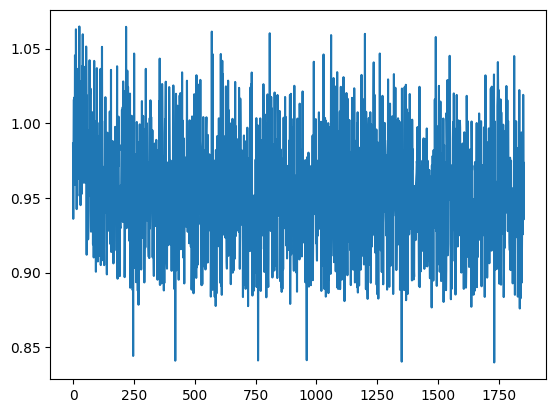

In [43]:
plt.plot(losses)

In [44]:
y_hat

tensor([[ 0.0597],
        [-0.0129],
        [ 0.1924],
        ...,
        [ 0.1042],
        [ 0.0688],
        [ 0.1097]], device='cuda:0', grad_fn=<AddmmBackward0>)

In [45]:
y

tensor([[-1.8810],
        [-0.8641],
        [ 0.8771],
        ...,
        [-0.4476],
        [ 0.3035],
        [ 0.5056]], device='cuda:0')

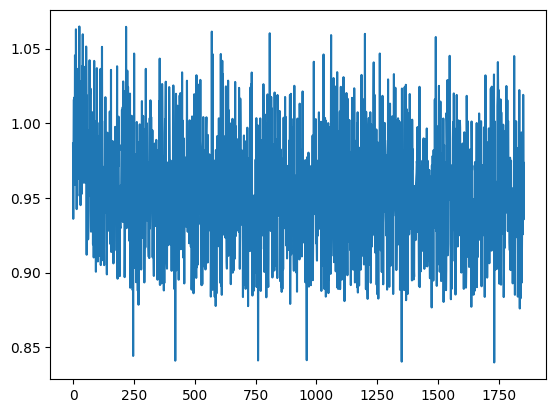

In [46]:
plt.plot(losses)

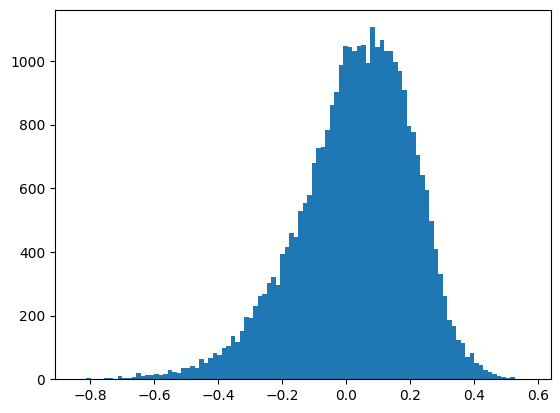

In [47]:
plt.hist(y_hat.detach().cpu().numpy(), bins=100);
# np.xscale('log')

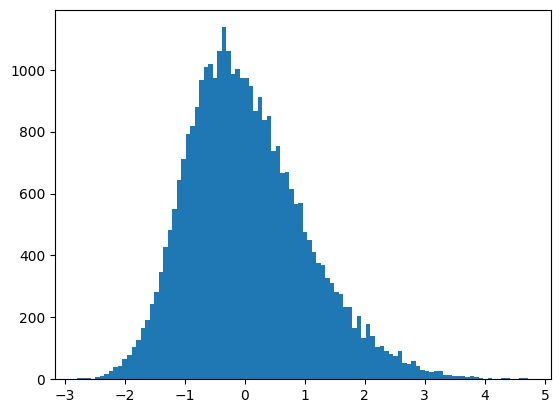

In [48]:
plt.hist(y.detach().cpu().numpy(), bins=100);
# np.xscale('log')

In [49]:
z = y.detach().cpu().numpy()
x.mean(), z.var()

(tensor(-0.4239, device='cuda:0'), 0.9929579)

(array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]]),
 array([-2.78632188, -2.63610168, -2.48588148, -2.33566128, -2.18544108,
        -2.03522089, -1.88500069, -1.73478049, -1.58456029, -1.43434009,
        -1.28411989, -1.13389969, -0.98367949, -0.8334593 , -0.6832391 ,
        -0.5330189 , -0.3827987 , -0.2325785 , -0.0823583 ,  0.0678619 ,
         0.21808209,  0.36830229,  0.51852249,  0.66874269,  0.81896289,
         0.96918309,  1.11940329,  1.26962348,  1.41984368,  1.57006388,
         1.72028408,  1.87050428,  2.02072448,  2.17094468,  2.32116488,
         2.47138507,  2.62160527,  2.77182547,  2.92204567,  3.07226587,
         3.22248607,  3.37270627,  3.52292646,  3.67314666,  3.82336686,
         3.97358706,  4.12380726,  4.27402746,  4.42424766,  4.57446785,
         4.72468805])

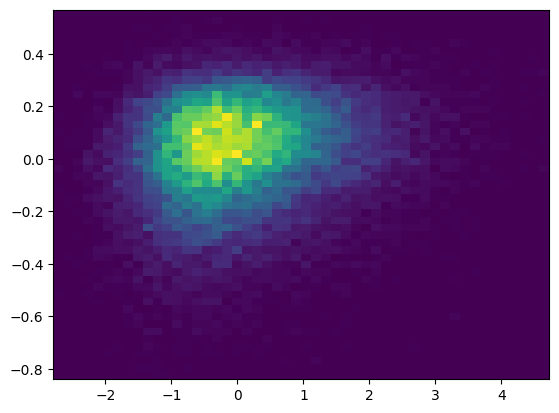

In [50]:
plt.hist2d(y.detach().cpu().numpy().ravel(), y_hat.detach().cpu().numpy().ravel(), bins=50)

In [51]:
y.detach().cpu().numpy()

array([[-1.8810236 ],
       [-0.864133  ],
       [ 0.8770899 ],
       ...,
       [-0.44756293],
       [ 0.3035072 ],
       [ 0.50563663]], dtype=float32)

In [52]:
import scipy.stats as stats

stats.pearsonr(y.detach().cpu().numpy().flatten(), y_hat.detach().cpu().numpy().flatten())

PearsonRResult(statistic=0.14526702040163997, pvalue=5.3611480475262014e-154)